# KV-cache offload eviction: GPU benchmark (vLLM 0.30, Colab)

Measures **time-to-first-token (TTFT)** and **prefix-cache hit rate** for different eviction
policies in vLLM's **CPU KV-offload tier**, replaying real production traffic
(Mooncake / Kimi traces, FAST'25) with real arrival times.

| config | what runs |
|---|---|
| `nocache` | prefix caching off (recompute everything) |
| `gpu` | vLLM GPU prefix cache only (stock) |
| `lru` | + CPU offload tier, vLLM's LRU (default) |
| `adm2` | + CPU tier, vLLM's `store_threshold=2` admission filter |
| `dip` | + CPU tier, **DIP-KV (ours)**: probation + ghost list, adaptive vs LRU |
| `arc`, `pg` | extended: vLLM's ARC (checks the T1-collapse finding on GPU), DIP without the adaptive switch |

**Before you start:** Runtime → Change runtime type → **A100 GPU** (High-RAM on).
Budget: the core grid takes about **2–3 h on an A100 (~15 compute units)**; the extended grid adds ~1.5 h.
Every run saves to Google Drive and the grid **resumes** where it left off if Colab disconnects:
just re-run the cells. Keep this tab open (Colab Pro has no background execution).

In [2]:
# 1. Hardware check
!nvidia-smi --query-gpu=name,memory.total --format=csv
import psutil, shutil
ram = psutil.virtual_memory().total / 2**30
print(f"System RAM: {ram:.0f} GiB   free disk: {shutil.disk_usage('/content').free/2**30:.0f} GiB")
assert ram > 40, "Need High-RAM runtime (CPU KV tier uses ~8-15 GiB pinned memory)"

name, memory.total [MiB]
NVIDIA A100-SXM4-40GB, 40960 MiB
System RAM: 83 GiB   free disk: 193 GiB


In [3]:
# 2. Google Drive for results (survives disconnects)
from google.colab import drive
drive.mount('/content/drive')
RESULTS = '/content/drive/MyDrive/kv-offload-bench'
import os; os.makedirs(RESULTS, exist_ok=True); print(RESULTS)

Mounted at /content/drive
/content/drive/MyDrive/kv-offload-bench


In [28]:
# 3. Get the code. Push your local repo to GitHub first and set REPO_URL,
#    OR upload a zip of the repo to Drive and set REPO_ZIP.
REPO_URL = 'https://github.com/jaisurya27/kv-offload-eviction.git'
REPO_ZIP = '/content/drive/MyDrive/Prefix-KV-LLM-serving.zip'
REPO = '/content/Prefix-KV-LLM-serving'
import os, subprocess
if not os.path.exists(REPO):
    if 'YOUR_GITHUB_USER' not in REPO_URL:
        subprocess.run(['git', 'clone', REPO_URL, REPO], check=True)
    elif os.path.exists(REPO_ZIP):
        subprocess.run(['unzip', '-q', REPO_ZIP, '-d', '/content'], check=True)
    else:
        raise SystemExit('Set REPO_URL or upload REPO_ZIP')
else:
    subprocess.run(['git', '-C', REPO, 'pull'], check=False)
%cd {REPO}
!ls

def sh(*args):
    # run a command from the repo, streaming output; raise on failure
    import subprocess
    r = subprocess.run([str(a) for a in args], cwd=REPO)
    if r.returncode:
        raise RuntimeError(f'command failed ({r.returncode}): {args}')

/content/Prefix-KV-LLM-serving
bench  kvpolicy  README.md  scripts		   tests   vllm_stub
colab  kvsim	 results    scripts_get_traces.sh  traces


In [7]:
# 4. Install vLLM 0.30.0 (pinned: the policy plugin API is from this version). ~5 min.
#    vLLM runs as a subprocess, so no runtime restart is needed.
!pip install -q vllm==0.30.0 aiohttp pandas matplotlib 2>&1 | tail -3
!python -c "import vllm, torch; print('vllm', vllm.__version__, '| torch', torch.__version__, '| cuda', torch.cuda.is_available())"

numba-cuda 0.28.2 requires cuda-core<1.0.0,>=0.5.1, but you have cuda-core 1.2.1 which is incompatible.
cudf-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.65.0 which is incompatible.
cuml-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.65.0 which is incompatible.
vllm 0.30.0 | torch 2.13.0+cu130 | cuda True


In [8]:
# 5. Traces (public Mooncake/Kimi production traces) + sanity check that our
#    policies load through vLLM's official out-of-tree hook.
!bash scripts_get_traces.sh && ls -la traces
!python -c "from vllm.v1.kv_offload.cpu.policies.factory import CachePolicyFactory as F; [print(n, F.get_cache_policy_cls(n, 'kvpolicy.probe')) for n in ['LRUProbe','ARCProbe','DIPProbe','PGProbe']]"

total 8396
drwxr-xr-x  2 root root    4096 Oct 14 17:53 .
drwxr-xr-x 12 root root    4096 Oct 14 17:53 ..
-rw-r--r--  1 root root 3029533 Oct 14 17:53 conversation_trace.jsonl
-rw-r--r--  1 root root 1136313 Oct 14 17:53 synthetic_trace.jsonl
-rw-r--r--  1 root root 4415857 Oct 14 17:53 toolagent_trace.jsonl
WARNING 10-14 17:53:47 [factory.py:68] Loading out-of-tree cache policy. This API is experimental and subject to change in the future as we iterate the design.
INFO 10-14 17:53:47 [factory.py:73] Loading out-of-tree cache policy 'LRUProbe' from 'kvpolicy.probe'.
LRUProbe <class 'kvpolicy.probe._probe.<locals>.Probe'>
INFO 10-14 17:53:47 [factory.py:73] Loading out-of-tree cache policy 'ARCProbe' from 'kvpolicy.probe'.
ARCProbe <class 'kvpolicy.probe._probe.<locals>.Probe'>
INFO 10-14 17:53:47 [factory.py:73] Loading out-of-tree cache policy 'DIPProbe' from 'kvpolicy.probe'.
DIPProbe <class 'kvpolicy.probe._probe.<locals>.Probe'>
INFO 10-14 17:53:47 [factory.py:73] Loading out-of-tr

In [9]:
# 6. Simulator predictions for exactly these configs (CPU only, ~1 min).
#    Later we compare measured GPU hit rates against these.
import os
PRED = f'{RESULTS}/predictions.jsonl'
if not os.path.exists(PRED):
    for t, c in [('conversation', 500), ('toolagent', 500), ('conversation', 1000)]:
        sh('python', 'bench/predict.py', '--trace', f'traces/{t}_trace.jsonl', '--cpu-chunks', c, '--out', PRED)
print(open(PRED).read())

{"trace": "conversation_trace.jsonl", "cpu_chunks": 500, "requests": 2887, "duration_s": 3536.999, "prompt_tokens": 29846390, "lru": 0.066, "arc": 0.066, "adm2": 0.1067, "dip": 0.1196, "pg": 0.1199, "oracle": 0.2522}
{"trace": "toolagent_trace.jsonl", "cpu_chunks": 500, "requests": 5810, "duration_s": 3536.999, "prompt_tokens": 45793907, "lru": 0.3965, "arc": 0.3965, "adm2": 0.4283, "dip": 0.4327, "pg": 0.4334, "oracle": 0.522}
{"trace": "conversation_trace.jsonl", "cpu_chunks": 1000, "requests": 2887, "duration_s": 3536.999, "prompt_tokens": 29846390, "lru": 0.111, "arc": 0.111, "adm2": 0.1685, "dip": 0.1652, "pg": 0.1654, "oracle": 0.3278}



In [11]:
# 7. Smoke test (~5 min): 80 requests, DIP policy. Must show policy_loaded=DIPProbe,
#    0 errors and non-zero hit rate before you spend compute on the full grid.
sh('python', 'bench/run.py', '--trace', 'traces/conversation_trace.jsonl', '--config', 'dip',
   '--cpu-chunks', 500, '--limit', 80, '--speedup', 20, '--run-name', 'smoke_dip', '--out-root', RESULTS)
import json
s = json.load(open(f'{RESULTS}/smoke_dip/summary.json'))
print({k: s[k] for k in ['policy_loaded', 'cpu_capacity_chunks_actual', 'n_ok', 'n_errors',
                         'hit_rate_gpu_tokens', 'hit_rate_cpu_tokens', 'ttft_ms_p50']})
assert s['n_errors'] == 0 and s['policy_loaded'] == 'DIPProbe', 'check server.log in the run folder'

{'policy_loaded': 'DIPProbe', 'cpu_capacity_chunks_actual': 500, 'n_ok': 80, 'n_errors': 0, 'hit_rate_gpu_tokens': 0.044692095461290535, 'hit_rate_cpu_tokens': 0.0, 'ttft_ms_p50': 13643.771276500047}


In [12]:
# 8. Calibrate: measure this GPU's prefill throughput and choose the replay speed per trace
#    (no-cache load = 80% of capacity). Same speed is used for every config => fair comparison.
sh('python', 'bench/calibrate.py', '--out', f'{RESULTS}/calibration.json',
   '--traces', 'traces/conversation_trace.jsonl', 'traces/toolagent_trace.jsonl')
CAL = json.load(open(f'{RESULTS}/calibration.json')); CAL

{'gpu_prefill_tok_s': {'4096': 61334.52428361488, '12288': 49236.20461877331},
 'tok_s_used': 55285.364451194095,
 'util_target': 0.8,
 'speedup': {'conversation': 5.241, 'toolagent': 3.416},
 'replay_minutes_conversation': 11.2,
 'replay_minutes_toolagent': 17.3}

In [13]:
# 9. The grid. Ordered by importance; re-run this cell after any disconnect (finished runs are skipped).
import subprocess, time, json, os
CORE = [(t, c, 500) for t in ['conversation', 'toolagent'] for c in ['gpu', 'lru', 'dip', 'adm2']] \
     + [(t, 'nocache', 500) for t in ['conversation', 'toolagent']]
EXTENDED = [('conversation', 'arc', 500), ('conversation', 'pg', 500)] \
         + [('conversation', c, 1000) for c in ['lru', 'dip', 'adm2']]
RUN_EXTENDED = False
grid = CORE + (EXTENDED if RUN_EXTENDED else [])
t_start = time.time()
for i, (t, cfg, chunks) in enumerate(grid):
    sp = CAL['speedup'][t]
    name = f'{t}_{cfg}_c{chunks}_x{sp:g}'
    done = os.path.exists(f'{RESULTS}/{name}/summary.json')
    print(f'[{i+1}/{len(grid)}] {name}' + ('  (done, skipping)' if done else ''), flush=True)
    if done:
        continue
    r = subprocess.run(['python', 'bench/run.py', '--trace', f'traces/{t}_trace.jsonl', '--config', cfg,
                        '--cpu-chunks', str(chunks), '--speedup', str(sp), '--run-name', name,
                        '--out-root', RESULTS])
    if r.returncode:
        print(f'   !! run failed, see {RESULTS}/{name}/server.log -- continuing')
    print(f'   elapsed {(time.time()-t_start)/60:.0f} min', flush=True)

[1/10] conversation_gpu_c500_x5.241  (done, skipping)
[2/10] conversation_lru_c500_x5.241  (done, skipping)
[3/10] conversation_dip_c500_x5.241  (done, skipping)
[4/10] conversation_adm2_c500_x5.241  (done, skipping)
[5/10] toolagent_gpu_c500_x3.416  (done, skipping)
[6/10] toolagent_lru_c500_x3.416  (done, skipping)
[7/10] toolagent_dip_c500_x3.416
   elapsed 21 min
[8/10] toolagent_adm2_c500_x3.416
   elapsed 40 min
[9/10] conversation_nocache_c500_x5.241
   elapsed 57 min
[10/10] toolagent_nocache_c500_x3.416
   elapsed 81 min


In [14]:
!nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv; tail -n 3 {RESULTS}/grid.log

utilization.gpu [%], memory.used [MiB]
0 %, 0 MiB
tail: cannot open '/content/drive/MyDrive/kv-offload-bench/grid.log' for reading: No such file or directory


,trace_name,cpu_chunks,config,n_ok,n_errors,ttft_ms_p50,ttft_ms_p95,ttft_ms_p99,hit_rate_gpu_tokens,hit_rate_cpu_tokens,hit_rate_total_tokens,hit_rate_sim
8,conversation,500,nocache,2887,0,144877.707,271554.486,289412.457,0.000,0.000,0.000,NaN
0,conversation,500,gpu,2887,0,126270.208,237645.548,253547.714,0.052,0.000,0.052,NaN
1,conversation,500,lru,2887,0,122778.468,230191.355,245123.143,0.052,0.013,0.066,0.066
3,conversation,500,adm2,2887,0,104282.549,197556.732,211237.640,0.052,0.056,0.108,0.107
2,conversation,500,dip,2887,0,96989.427,186830.730,197868.055,0.052,0.075,0.127,0.120
9,toolagent,500,nocache,5810,0,133063.867,284899.009,296474.904,0.000,0.000,0.000,NaN
4,toolagent,500,gpu,5800,10,3532.000,10838.875,12356.801,0.345,0.000,0.345,NaN
5,toolagent,500,lru,5809,1,2022.965,6082.836,8129.691,0.349,0.047,0.396,0.396
7,toolagent,500,adm2,5808,2,1386.155,4689.781,6463.071,0.351,0.077,0.427,0.428
6,toolagent,500,dip,5810,0,1208.667,4550.364,6001.116,0.351,0.085,0.436,0.433


conversation c500 nocache  p50   144878 ms (-18.0% vs LRU)  p95   271554 ms (-18.0%)  hit 0.000
conversation c500 gpu      p50   126270 ms ( -2.8% vs LRU)  p95   237646 ms ( -3.2%)  hit 0.052
conversation c500 lru      p50   122778 ms ( +0.0% vs LRU)  p95   230191 ms ( +0.0%)  hit 0.066
conversation c500 adm2     p50   104283 ms (+15.1% vs LRU)  p95   197557 ms (+14.2%)  hit 0.108
conversation c500 dip      p50    96989 ms (+21.0% vs LRU)  p95   186831 ms (+18.8%)  hit 0.127
toolagent    c500 nocache  p50   133064 ms (-6477.7% vs LRU)  p95   284899 ms (-4583.7%)  hit 0.000
toolagent    c500 gpu      p50     3532 ms (-74.6% vs LRU)  p95    10839 ms (-78.2%)  hit 0.345
toolagent    c500 lru      p50     2023 ms ( +0.0% vs LRU)  p95     6083 ms ( +0.0%)  hit 0.396
toolagent    c500 adm2     p50     1386 ms (+31.5% vs LRU)  p95     4690 ms (+22.9%)  hit 0.427
toolagent    c500 dip      p50     1209 ms (+40.3% vs LRU)  p95     4550 ms (+25.2%)  hit 0.436


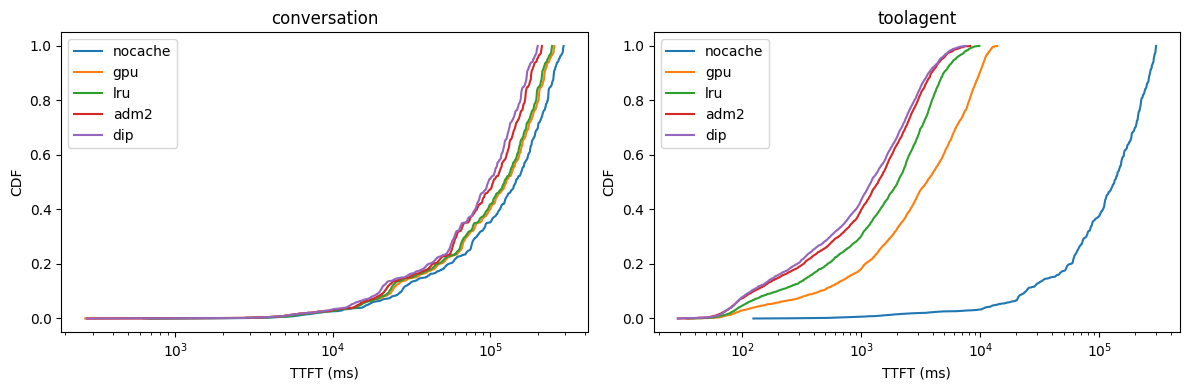

In [15]:
# 10. Results: table, measured vs simulated hit rate, TTFT plots (saved to Drive)
import glob, json, pandas as pd, numpy as np, matplotlib.pyplot as plt
rows = []
for f in glob.glob(f'{RESULTS}/*/summary.json'):
    if '/smoke_' in f: continue
    s = json.load(open(f)); s['run'] = f.split('/')[-2]; rows.append(s)
df = pd.DataFrame(rows)
pred = [json.loads(l) for l in open(PRED)]
def predicted(r):
    for p in pred:
        if p['trace'].startswith(r['trace'].split('/')[-1].split('_')[0]) and p['cpu_chunks'] == r['cpu_chunks']:
            return p.get(r['config'])
df['hit_rate_sim'] = df.apply(predicted, axis=1)
order = {'nocache': 0, 'gpu': 1, 'lru': 2, 'arc': 3, 'adm2': 4, 'pg': 5, 'dip': 6}
df['trace_name'] = df['trace'].str.extract(r'(\w+)_trace')[0]
df = df.sort_values(['trace_name', 'cpu_chunks', 'config'], key=lambda c: c.map(order) if c.name == 'config' else c)
cols = ['trace_name', 'cpu_chunks', 'config', 'n_ok', 'n_errors', 'ttft_ms_p50', 'ttft_ms_p95', 'ttft_ms_p99',
        'hit_rate_gpu_tokens', 'hit_rate_cpu_tokens', 'hit_rate_total_tokens', 'hit_rate_sim']
table = df[cols].round(3); table.to_csv(f'{RESULTS}/results_table.csv', index=False); display(table)

# TTFT reduction vs the stock CPU-tier LRU and vs no-cache
for (t, c), g in df.groupby(['trace_name', 'cpu_chunks']):
    base = g[g.config == 'lru']
    if len(base):
        b = base.iloc[0]
        for _, r in g.iterrows():
            print(f"{t:12s} c{c} {r.config:8s} p50 {r.ttft_ms_p50:8.0f} ms ({100*(1-r.ttft_ms_p50/b.ttft_ms_p50):+5.1f}% vs LRU)  "
                  f"p95 {r.ttft_ms_p95:8.0f} ms ({100*(1-r.ttft_ms_p95/b.ttft_ms_p95):+5.1f}%)  hit {r.hit_rate_total_tokens:.3f}")

fig, axes = plt.subplots(1, df.trace_name.nunique(), figsize=(12, 4), squeeze=False)
for ax, (t, g) in zip(axes[0], df[df.cpu_chunks == 500].groupby('trace_name')):
    for _, r in g.iterrows():
        x = [json.loads(l)['ttft_s'] for l in open(f"{RESULTS}/{r.run}/requests.jsonl")]
        x = np.sort([v for v in x if v is not None]) * 1000
        ax.plot(x, np.linspace(0, 1, len(x)), label=r.config)
    ax.set_xscale('log'); ax.set_xlabel('TTFT (ms)'); ax.set_ylabel('CDF'); ax.set_title(t); ax.legend()
plt.tight_layout(); plt.savefig(f'{RESULTS}/ttft_cdf.png', dpi=150); plt.show()

In [18]:
# 11. ARC check (extended grid): vLLM's ARC promotes every new chunk to T2 because the
#     connector re-touches keys after storing them. Look at T1 size inside the real engine.
import glob
for f in glob.glob(f'{RESULTS}/*_arc_*/policy.log'):
    recs = [json.loads(l) for l in open(f)]
    print(f.split('/')[-2], [(r.get('arc_t1'), r.get('arc_t2')) for r in recs if r['event'] == 'periodic'][-5:])

In [30]:
import json
CAL = json.load(open(f'{RESULTS}/calibration.json'))
SP = round(CAL['speedup']['conversation'] / 2, 3)   # 2.62
cmds = [f"python bench/run.py --trace traces/conversation_trace.jsonl --config {c} --cpu-chunks 500 "
        f"--speedup {SP} --run-name conversation_{c}_c500_x{SP:g} --out-root {RESULTS} || echo 'FAILED {c}'"
        for c in ['gpu', 'lru', 'dip', 'adm2']]
open('/content/grid2.sh', 'w').write('cd /content/Prefix-KV-LLM-serving\n' + '\n'.join(cmds) + '\necho GRID DONE\n')
!nohup bash /content/grid2.sh > {RESULTS}/grid2.log 2>&1 &
print('launched, speed', SP)

launched, speed 2.62


In [35]:
!tail -n 3 {RESULTS}/grid2.log; echo ---; ps aux | grep -c "[b]ench/run.py"; nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv

 "hit_rate_from_usage": 0.10748066369127375
}
GRID DONE
---
0
utilization.gpu [%], memory.used [MiB]
0 %, 0 MiB


In [36]:
import json, glob, numpy as np
for f in sorted(glob.glob(f'{RESULTS}/conversation_*_x2.62/summary.json')):
    s = json.load(open(f)); d = s['metrics_delta']
    x = [r['ttft_s'] for r in map(json.loads, open(f.replace('summary.json', 'requests.jsonl'))) if r['ttft_s']]
    n = len(x)//10
    print(f"{s['config']:5s} ok={s['n_ok']} err={s['n_errors']} p50={s['ttft_ms_p50']:.0f} p95={s['ttft_ms_p95']:.0f} "
          f"| first10%={np.median(x[:n]):.2f}s last10%={np.median(x[-n:]):.2f}s "
          f"| gpu={s['hit_rate_gpu_tokens']:.3f} cpu={s['hit_rate_cpu_tokens']:.3f} usage={s['hit_rate_from_usage'] or 0:.3f}")
    print('      ', {k.split(':')[1]: int(v) for k, v in d.items()})

adm2  ok=2886 err=1 p50=711 p95=2714 | first10%=0.66s last10%=0.96s | gpu=0.052 cpu=0.056 usage=0.107
       {'prefix_cache_queries': 29815670, 'prefix_cache_hits': 1548640, 'external_prefix_cache_queries': 28267030, 'external_prefix_cache_hits': 1655968}
dip   ok=2886 err=1 p50=686 p95=2591 | first10%=0.62s last10%=0.92s | gpu=0.052 cpu=0.075 usage=0.127
       {'prefix_cache_queries': 29834581, 'prefix_cache_hits': 1555344, 'external_prefix_cache_queries': 28279237, 'external_prefix_cache_hits': 2225664}
gpu   ok=2882 err=5 p50=812 p95=2955 | first10%=0.71s last10%=1.02s | gpu=0.052 cpu=0.000 usage=0.052
       {'prefix_cache_queries': 29788635, 'prefix_cache_hits': 1546592, 'external_prefix_cache_queries': 0, 'external_prefix_cache_hits': 0}
lru   ok=2886 err=1 p50=806 p95=2979 | first10%=0.66s last10%=1.12s | gpu=0.052 cpu=0.014 usage=0.066
       {'prefix_cache_queries': 29834581, 'prefix_cache_hits': 1548640, 'external_prefix_cache_queries': 28285941, 'external_prefix_cache_hits'

,trace,config,ok,err,p50_ms,p95_ms,p99_ms,hit_gpu,hit_cpu,hit_total,hit_sim,first10_s,last10_s,p50_vs_lru_%,p95_vs_lru_%
0,conversation,gpu,2882,5,812,2955,4263,0.052,0.000,0.052,NaN,0.71,1.02,-0.7,0.8
1,conversation,lru,2886,1,806,2979,4310,0.052,0.014,0.066,0.0660,0.66,1.12,0.0,0.0
3,conversation,adm2,2886,1,711,2714,3879,0.052,0.056,0.107,0.1067,0.66,0.96,11.8,8.9
2,conversation,dip,2886,1,686,2591,3693,0.052,0.075,0.127,0.1196,0.62,0.92,14.9,13.0
8,toolagent,nocache,5810,0,133064,284899,296475,0.000,0.000,0.000,NaN,13.67,284.90,-6477.6,-4583.5
4,toolagent,gpu,5800,10,3532,10839,12357,0.345,0.000,0.345,NaN,2.65,9.23,-74.6,-78.2
5,toolagent,lru,5809,1,2023,6083,8130,0.349,0.047,0.396,0.3965,1.35,2.10,0.0,0.0
7,toolagent,adm2,5808,2,1386,4690,6463,0.351,0.077,0.427,0.4283,1.16,1.47,31.5,22.9
6,toolagent,dip,5810,0,1209,4550,6001,0.351,0.085,0.436,0.4327,1.07,1.25,40.2,25.2


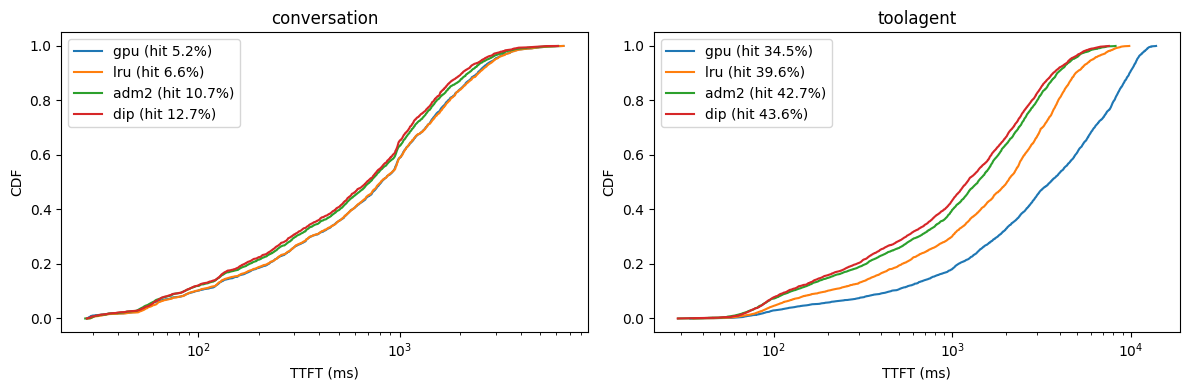

In [37]:
import glob, json, numpy as np, pandas as pd, matplotlib.pyplot as plt
CAL = json.load(open(f'{RESULTS}/calibration.json'))
SEL = {'conversation': 'x2.62', 'toolagent': f"x{CAL['speedup']['toolagent']:g}"}
pred = {json.loads(l)['trace'].split('_')[0]: json.loads(l) for l in open(f'{RESULTS}/predictions.jsonl')
        if json.loads(l)['cpu_chunks'] == 500}
rows = []
for t, tag in SEL.items():
    for f in glob.glob(f'{RESULTS}/{t}_*_c500_{tag}/summary.json'):
        s = json.load(open(f)); run = f.split('/')[-2]
        x = [r['ttft_s'] for r in map(json.loads, open(f.replace('summary.json', 'requests.jsonl'))) if r['ttft_s']]
        n = len(x) // 10
        rows.append(dict(trace=t, config=s['config'], run=run, ok=s['n_ok'], err=s['n_errors'],
                         p50_ms=round(s['ttft_ms_p50']), p95_ms=round(s['ttft_ms_p95']), p99_ms=round(s['ttft_ms_p99']),
                         hit_gpu=round(s['hit_rate_gpu_tokens'], 3), hit_cpu=round(s['hit_rate_cpu_tokens'], 3),
                         hit_total=round(s['hit_rate_total_tokens'], 3), hit_sim=pred[t].get(s['config']),
                         first10_s=round(np.median(x[:n]), 2), last10_s=round(np.median(x[-n:]), 2)))
order = ['nocache', 'gpu', 'lru', 'adm2', 'dip']
df = pd.DataFrame(rows).sort_values(['trace', 'config'], key=lambda c: c.map(order.index) if c.name == 'config' else c)
for t, g in df.groupby('trace'):
    b = g[g.config == 'lru'].iloc[0]
    df.loc[g.index, 'p50_vs_lru_%'] = (100 * (1 - g.p50_ms / b.p50_ms)).round(1)
    df.loc[g.index, 'p95_vs_lru_%'] = (100 * (1 - g.p95_ms / b.p95_ms)).round(1)
display(df.drop(columns='run')); df.to_csv(f'{RESULTS}/final_results.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (t, g) in zip(axes, df.groupby('trace')):
    for _, r in g[g.config != 'nocache'].iterrows():
        x = np.sort([v['ttft_s'] for v in map(json.loads, open(f"{RESULTS}/{r.run}/requests.jsonl")) if v['ttft_s']]) * 1000
        ax.plot(x, np.linspace(0, 1, len(x)), label=f"{r.config} (hit {r.hit_total:.1%})")
    ax.set_xscale('log'); ax.set_xlabel('TTFT (ms)'); ax.set_ylabel('CDF'); ax.set_title(t); ax.legend()
plt.tight_layout(); plt.savefig(f'{RESULTS}/final_ttft_cdf.png', dpi=150); plt.show()

In [29]:
!pkill -f grid2.sh; pkill -f bench/run.py; pkill -f "vllm serve"; sleep 5
!nvidia-smi --query-gpu=memory.used --format=csv
!rm -rf {RESULTS}/conversation_*_x2.62
!grep -c "acquire_lock" bench/run.py

^C
memory.used [MiB]
0 MiB
2


## Reading the results
* **hit_rate_total_tokens** = (GPU + CPU-tier prefix hits) / prompt tokens, from vLLM's own Prometheus counters.
  `hit_rate_sim` is the offline simulator's prediction for the CPU tier; the two should be close
  (the GPU tier in front is small and inclusive).
* TTFT includes queueing, so a few points of hit rate can move p95 a lot under load.
* Setup caveats to state honestly: Qwen2.5-1.5B-Instruct on one A100; 1/4 session sample of each trace
  with CPU capacity scaled by 1/4; prompts truncated to 30k tokens; outputs capped at 64 tokens;
  token contents are synthetic (the traces publish only block hashes), sharing structure is real.